In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
import pandas as pd

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import matplotlib.lines as mlines
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
import matplotlib.colors as mcolors
from cartopy.mpl.patch import geos_to_path
import matplotlib.patches as mpatches 
from matplotlib.path import Path
from matplotlib.ticker import MaxNLocator

In [2]:
def add_graticule(ax, lat_labels=False, lon_labels=True):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=0.6, color='gray', alpha=0.6, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.top_labels = gl.right_labels = False
    gl.bottom_labels = lon_labels
    gl.left_labels = lat_labels
    gl.xlabel_style = {'size': 7}
    gl.ylabel_style = {'size': 7}
    # gl.xpadding = 1.5 
    return gl

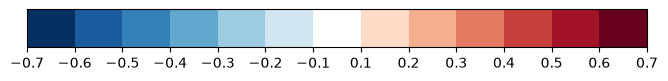

In [3]:
levels = np.array([-0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 
                   0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7])

neg_levels = levels[levels < -0.1]
pos_levels = levels[levels >  0.1]
n_neg = len(neg_levels)
n_pos = len(pos_levels)

cmap_full = plt.get_cmap('RdBu_r')
neg_colors = cmap_full(np.linspace(0.0, 0.4, n_neg))
pos_colors = cmap_full(np.linspace(0.6, 1.0, n_pos))

colors = list(neg_colors) + ['white'] + list(pos_colors)  # one white bin from -0.1 to 0.1

cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=levels, ncolors=len(colors))

fig, ax = plt.subplots(figsize=(8, 1))
fig.subplots_adjust(bottom=0.5)

cb = plt.colorbar(
    mappable=plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=ax,
    orientation='horizontal',
    ticks=levels,
    spacing='uniform',
    extend='neither'
)

In [20]:
dataset1 = xr.open_dataset("Figure1_1.nc")
dataset2 = xr.open_dataset("Figure1_2.nc")
dataset3 = xr.open_dataset("Figure1_3.nc")
dataset4 = xr.open_dataset("Figure1_4.nc")

ds = [
    [dataset1.hadley_trend, dataset1.cmip6_trend, ],
    [[dataset2.hist_zgrad, dataset2.cmip6_zgrad, dataset2.hadley_zgrad], 
     [dataset2.hist_mgrad, dataset2.cmip6_mgrad, dataset2.hadley_mgrad]], 
    [dataset3.sst_ipo.mean('month'), dataset4.sst_amo.mean('month')]
]
labels = [ ['a', 'd'], ['b', 'e'], ['c', 'f'],]
time_year_hist = [np.datetime64(f'{iyear}-06') for iyear in np.arange(1960, 2021, 1)]
time_year = [np.datetime64(f'{iyear}-06') for iyear in np.arange(2014,2051,1)]
ice_mask = dataset1.ice_mask

/tmp/ipykernel_2240892/3051991643.py:44: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex instead of a 'ns'-resolution DatetimeIndex. This warning can be silenced by explicitly passing the `time_unit` keyword argument.
  ax.plot(ds_now[0]['time_hist'].indexes['time_hist'].to_datetimeindex(), ds_now[0], color='k', linewidth=1.2, alpha=0.2)
/tmp/ipykernel_2240892/3051991643.py:44: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  ax.plot(ds_now[0]['time_hist'].indexes['time_hist'].to_datetimeindex(), ds_now[0], color='k', linewidth=1.2, alpha=0.2)
/tmp/ipykernel_2240892/3051991643.py:44: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex inste

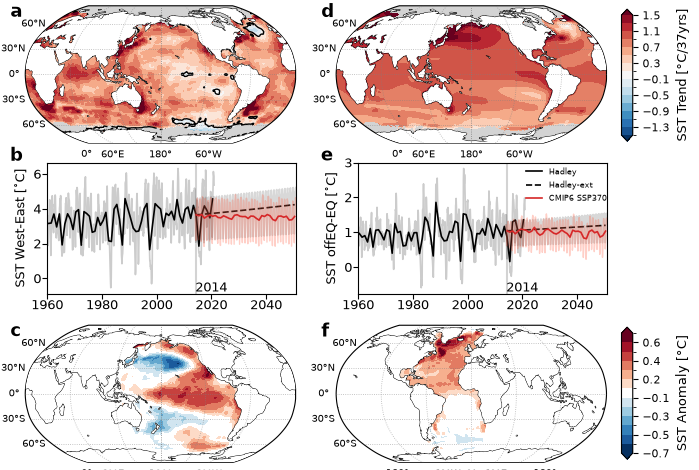

In [10]:
fig = plt.figure(figsize=(7.5, 6))
gs = GridSpec(3, 2, figure=fig, hspace=0.12, wspace=0.15)
axs_r1 = [fig.add_subplot(gs[0,i], projection=ccrs.Robinson(central_longitude=180)) for i in range(2)]
axs_r2 = [fig.add_subplot(gs[1,i]) for i in range(2)]
axs_r3 = [fig.add_subplot(gs[2,0], projection=ccrs.Robinson(central_longitude=180)), 
          fig.add_subplot(gs[2,1], projection=ccrs.Robinson()), ]

### ROW1: SST trends in Hadley & CMIP6 during 2014-2050
for i in range(2):
    ds_now = ds[0][i]
    ax = axs_r1[i]
    p1 = ds_now.plot.contourf(
        ax=ax, levels=np.linspace(-1.5, 1.5, 16), extend='both',
        transform=ccrs.PlateCarree(), add_colorbar=False, 
    )
    ds_now.plot.contour(
        ax=ax, levels=[0], colors='black', linewidths=1.0, 
        transform=ccrs.PlateCarree(), add_colorbar=False, 
    )
    my_icemask = xr.where(ice_mask==0, np.nan, 1.0)
    my_icemask.plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), levels=[0.5, 1.5], 
        colors=["lightgrey"], add_colorbar=False)
    ax.annotate(
        labels[0][i], xy=(-0.055, 1.02), xycoords='axes fraction',
        fontsize=13, fontweight='bold', ha='left', va='top'
    )
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    add_graticule(ax, lat_labels=True, lon_labels=True)

### ROW2: SST trends in Hadley & CMIP6 during 2014-2050
shrink_w=0.92; shrink_h=0.92
for i in range(2):
    ax = axs_r2[i]
    p = ax.get_position()
    new_w = p.width * shrink_w; new_h = p.height * shrink_h
    new_x0 = p.x0 + 0.5 * (p.width - new_w)
    new_y0 = p.y0 + 0.5 * (p.height - new_h)
    ax.set_position([new_x0+0.015, new_y0+0.01, new_w, new_h])
    ds_now = ds[1][i]
    ax.axvline(np.datetime64('2014-06'), color='lightgray')
    ds_now[2].plot(color='gray', linewidth=1.2, ax=ax, alpha=0.3)
    ax.plot(ds_now[0]['time_hist'].indexes['time_hist'].to_datetimeindex(), ds_now[0], color='k', linewidth=1.2, alpha=0.2)
    ax.plot(time_year_hist, ds_now[0].groupby('time_hist.year').mean(), label='Hadley', color='k', linewidth=1.2,)
    ax.plot(time_year, ds_now[2].groupby('time_future.year').mean(), label='Hadley-ext', color='k', linewidth=1.2, linestyle='--')
    ds_now[1].plot(color='tomato', linewidth=1.0, ax=ax, alpha=0.3)
    ax.plot(time_year, ds_now[1].groupby('time_future.year').mean(), label='CMIP6 SSP370', color='tab:red', linewidth=1.2, zorder=100)
    ax.set_xlabel(None)
    ax.set_ylabel('SST West-East [$^{\circ}$C]' if i==0 else 'SST offEQ-EQ [$^{\circ}$C]', fontsize=9)
    ax.set_xlim(np.datetime64('1960-01'), np.datetime64('2050-12'))
    ticks = ax.get_xticks()
    ax.set_xticks(ticks[::2])
    ax.tick_params(axis='x', labelsize=9, pad=0.8)
    ax.tick_params(axis='y', labelsize=9, pad=0.8)
    ax.annotate('2014', (0.595, 0.017), xycoords='axes fraction', fontsize=9)
    ax.annotate(
        labels[1][i], xy=(-0.15, 1.12), xycoords='axes fraction', fontsize=13, fontweight='bold', ha='left', va='top'
    )
ax.legend(loc='upper right', bbox_to_anchor=(1.03, 1.02), fontsize=6, frameon=False)

### ROW3: IPO & AMO SST anomalies
for i in range(2):
    ds_now = ds[2][i]
    ax = axs_r3[i]
    p2 = ds_now.plot.contourf(
        ax=ax, levels=levels, cmap=cmap, extend='both',
        transform=ccrs.PlateCarree(), add_colorbar=False, 
    )
    ax.annotate(
        labels[2][i], xy=(-0.055, 1.02), xycoords='axes fraction',
        fontsize=13, fontweight='bold', ha='left', va='top'
    )
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
    add_graticule(ax, lat_labels=True, lon_labels=True)

cbar_ax1 = fig.add_axes([0.92, 0.65, 0.015, 0.22])
cbar = fig.colorbar(p1, cax=cbar_ax1)
cbar.set_label('SST Trend [°C/37yrs]', fontsize=9)
cbar.ax.tick_params(labelsize=8)
cbar_ax2 = fig.add_axes([0.92, 0.12, 0.015, 0.22])
cbar = fig.colorbar(p2, cax=cbar_ax2)
cbar.set_label('SST Anomaly [°C]', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# plt.savefig(f'Figure1.png', bbox_inches='tight', dpi=300, pad_inches=0.13)

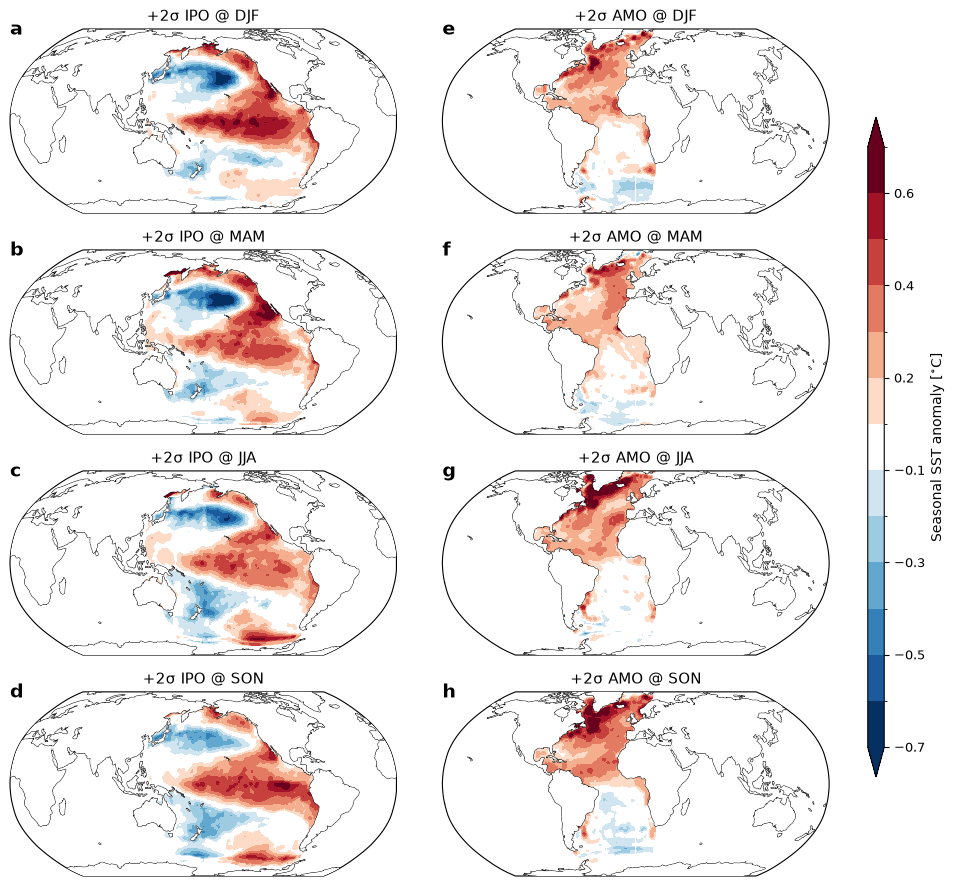

In [21]:
fig = plt.figure(figsize=(11,11))
gs = GridSpec(4, 2, figure=fig, wspace=0.03)
axs = [[fig.add_subplot(gs[ii,0], projection=ccrs.Robinson(central_longitude=180)), 
       fig.add_subplot(gs[ii,1], projection=ccrs.Robinson()), ] for ii in range(4)]

# IPO
ds1 = [    
    dataset3.sst_ipo.sel(month=[12,1,2]).mean('month'), 
    dataset3.sst_ipo.sel(month=[3,4,5]).mean('month'), 
    dataset3.sst_ipo.sel(month=[6,7,8]).mean('month'), 
    dataset3.sst_ipo.sel(month=[9,10,11]).mean('month'), 
]
# Var2
ds2 = [    
    dataset4.sst_amo.sel(month=[12,1,2]).mean('month'), 
    dataset4.sst_amo.sel(month=[3,4,5]).mean('month'), 
    dataset4.sst_amo.sel(month=[6,7,8]).mean('month'), 
    dataset4.sst_amo.sel(month=[9,10,11]).mean('month'), 
]
numbers = [['a', 'b', 'c', 'd',], ['e', 'f', 'g', 'h']]   # [column1, column2]
titles = ['DJF', 'MAM', 'JJA', 'SON']

for irow in range(4):
    ipo_now = ds1[irow].sel(lat=slice(-80, 80)); amo_now = ds2[irow].sel(lat=slice(-80, 80))

    p2 = ipo_now.plot.contourf(
        ax=axs[irow][0], levels=levels, cmap=cmap, extend='both',
        transform=ccrs.PlateCarree(), add_colorbar=False, 
    )
    p2 = amo_now.plot.contourf(
        ax=axs[irow][1], levels=levels, cmap=cmap, extend='both',
        transform=ccrs.PlateCarree(), add_colorbar=False, 
    )
    

for icol in range(2):
    for irow in range(4):
        ax = axs[irow][icol]
        ax.coastlines(linewidth=0.7)
        ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
        ax.set_title(f'+2σ IPO @ {titles[irow]}' if icol==0 else f'+2σ AMO @ {titles[irow]}', fontsize=11)
        ax.annotate(numbers[icol][irow], xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
        # add_graticule(ax, lat_labels=False, lon_labels=False)
        
cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(p2, cax=cax)
cbar.ax.tick_params(labelsize=9)
cbar.set_label('Seasonal SST anomaly [$^{\circ}$C]')

# plt.savefig(f'FigureS1.png', bbox_inches='tight', dpi=300)